In [3]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.neural_network import MLPClassifier


In [4]:
# Function to load SVHN dataset
def load_svhn_data(path):
    data = loadmat(path)
    images = data['X']
    labels = data['y']
    images = np.moveaxis(images, -1, 0)  # Move the channel axis to the first dimension
    labels[labels == 10] = 0  # Replace label 10 with 0 to match array indexing
    return images, labels.flatten()

# Download the SVHN dataset manually
!wget http://ufldl.stanford.edu/housenumbers/train_32x32.mat
!wget http://ufldl.stanford.edu/housenumbers/test_32x32.mat

# Load the dataset from the local file system
train_images, train_labels = load_svhn_data('train_32x32.mat')
test_images, test_labels = load_svhn_data('test_32x32.mat')

# Normalize the pixel values to be between 0 and 1
train_images, test_images = train_images / 255.0, test_images / 255.0

# Flatten images for baseline models
train_images_flat = train_images.reshape((train_images.shape[0], -1))
test_images_flat = test_images.reshape((test_images.shape[0], -1))

# Print shapes to verify
print('Training data shape:', train_images.shape, train_labels.shape)
print('Test data shape:', test_images.shape, test_labels.shape)
print('Flattened training data shape:', train_images_flat.shape)
print('Flattened test data shape:', test_images_flat.shape)


--2024-05-20 15:34:11--  http://ufldl.stanford.edu/housenumbers/train_32x32.mat
Resolving ufldl.stanford.edu (ufldl.stanford.edu)... 171.64.68.10
Connecting to ufldl.stanford.edu (ufldl.stanford.edu)|171.64.68.10|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 182040794 (174M) [text/plain]
Saving to: ‘train_32x32.mat’

train_32x32.mat     100%[===================>] 173.61M  12.5MB/s    in 13s     

2024-05-20 15:34:24 (12.9 MB/s) - ‘train_32x32.mat’ saved [182040794/182040794]

--2024-05-20 15:34:25--  http://ufldl.stanford.edu/housenumbers/test_32x32.mat
Resolving ufldl.stanford.edu (ufldl.stanford.edu)... 171.64.68.10
Connecting to ufldl.stanford.edu (ufldl.stanford.edu)|171.64.68.10|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 64275384 (61M) [text/plain]
Saving to: ‘test_32x32.mat’

test_32x32.mat      100%[===================>]  61.30M  11.1MB/s    in 8.2s    

2024-05-20 15:34:33 (7.48 MB/s) - ‘test_32x32.mat’ saved [64275384/64

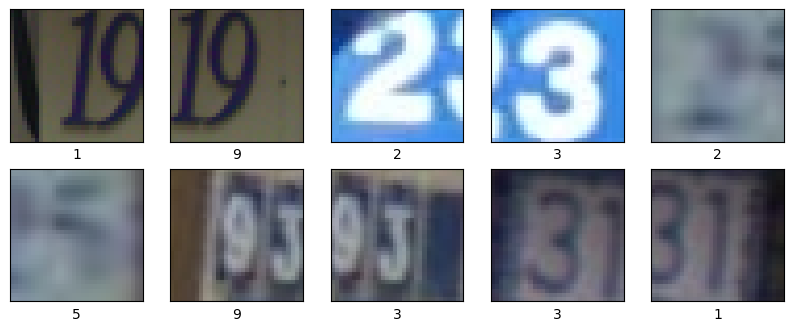

In [3]:
# Visualize the first 10 images from the training set
plt.figure(figsize=(10,10))
for i in range(10):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i])

    # Use the numerical label instead of the class name
    plt.xlabel(str(train_labels[i]))
plt.show()

In [10]:
# Train a Logistic Regression model
logistic_regression = LogisticRegression(max_iter=1000)
logistic_regression.fit(train_images_flat, train_labels)

# Evaluate the model
logistic_pred = logistic_regression.predict(test_images_flat)
logistic_acc = accuracy_score(test_labels, logistic_pred)
print(f'Logistic Regression accuracy: {logistic_acc}')


/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression accuracy: 0.2576444376152428


In [11]:
# Train a simple feedforward neural network (MLP)
mlp = MLPClassifier(hidden_layer_sizes=(64,), max_iter=10, verbose=True)
mlp.fit(train_images_flat, train_labels)

# Evaluate the model
mlp_pred = mlp.predict(test_images_flat)
mlp_acc = accuracy_score(test_labels, mlp_pred)
print(f'Feedforward Neural Network accuracy: {mlp_acc}')


Iteration 1, loss = 2.25909076
Iteration 2, loss = 2.21421869
Iteration 3, loss = 2.11994972
Iteration 4, loss = 1.94460020
Iteration 5, loss = 1.82987241
Iteration 6, loss = 1.75880854
Iteration 7, loss = 1.71324267
Iteration 8, loss = 1.68934346
Iteration 9, loss = 1.66643815
Iteration 10, loss = 1.65659220


/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:686: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (10) reached and the optimization hasn't converged yet.
  warnings.warn(


Feedforward Neural Network accuracy: 0.41956054087277195


In [12]:
# Define the CNN model
model = models.Sequential()
model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))

model.add(layers.Flatten())
model.add(layers.Dense(64, activation='relu'))
model.add(layers.Dense(10))

model.summary()

# Compile and train the CNN model
model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

history = model.fit(train_images, train_labels, epochs=10,
                    validation_data=(test_images, test_labels))

# Evaluate the CNN model
test_loss, test_acc = model.evaluate(test_images, test_labels, verbose=2)
print(f'CNN accuracy: {test_acc}')


Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 30, 30, 32)        896       
                                                                 
 max_pooling2d (MaxPooling2  (None, 15, 15, 32)        0         
 D)                                                              
                                                                 
 conv2d_1 (Conv2D)           (None, 13, 13, 64)        18496     
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 6, 6, 64)          0         
 g2D)                                                            
                                                                 
 conv2d_2 (Conv2D)           (None, 4, 4, 64)          36928     
                                                                 
 flatten (Flatten)           (None, 1024)              0

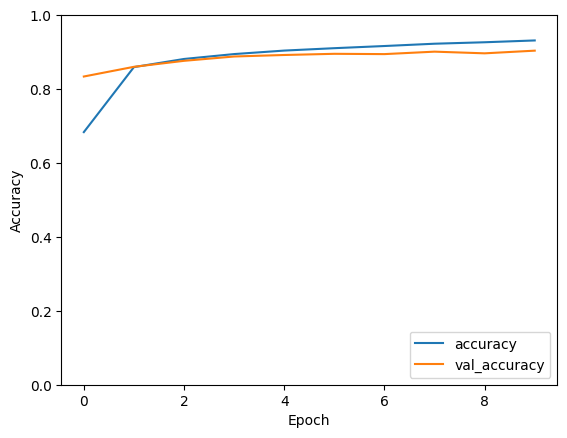

In [13]:
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label='val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0, 1])
plt.legend(loc='lower right')
plt.show()


814/814 [==============================] - 16s 19ms/step


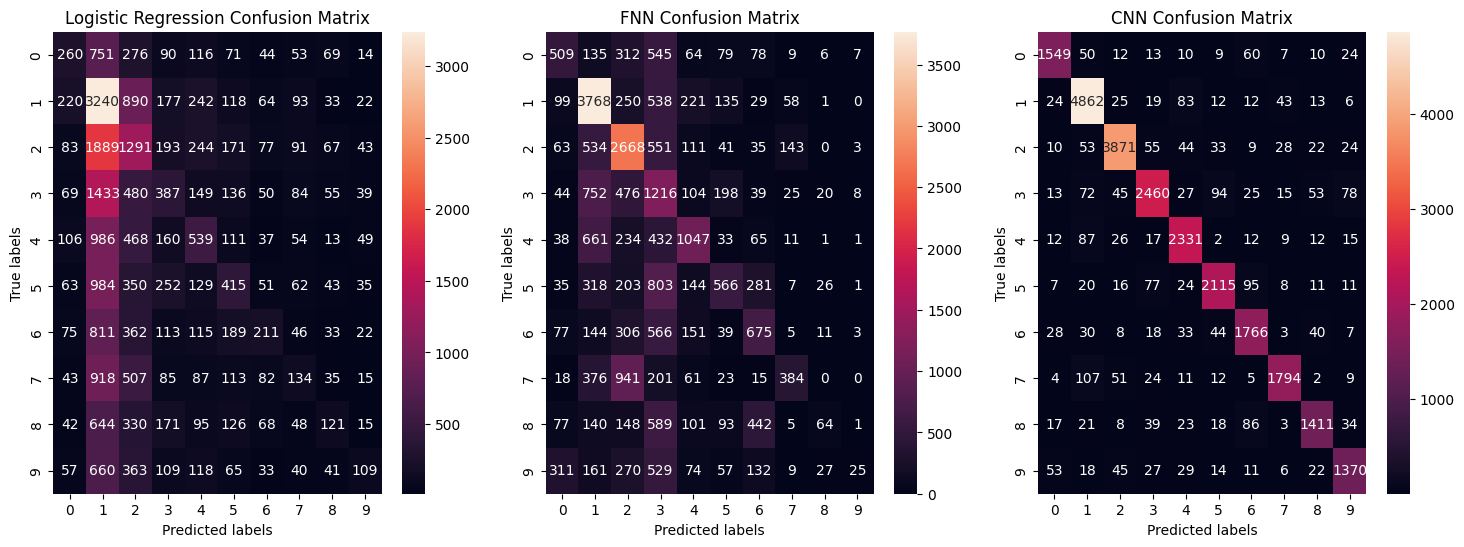

In [15]:
# Import necessary modules
from sklearn.metrics import confusion_matrix
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Generate confusion matrices
logistic_cm = confusion_matrix(test_labels, logistic_pred)
mlp_cm = confusion_matrix(test_labels, mlp_pred)
cnn_pred = np.argmax(model.predict(test_images), axis=1)
cnn_cm = confusion_matrix(test_labels, cnn_pred)

# Plot confusion matrices
fig, ax = plt.subplots(1, 3, figsize=(18, 6))

sns.heatmap(pd.DataFrame(logistic_cm), annot=True, fmt='g', ax=ax[0])
ax[0].set_title('Logistic Regression Confusion Matrix')
ax[0].set_xlabel('Predicted labels')
ax[0].set_ylabel('True labels')

sns.heatmap(pd.DataFrame(mlp_cm), annot=True, fmt='g', ax=ax[1])
ax[1].set_title('FNN Confusion Matrix')
ax[1].set_xlabel('Predicted labels')
ax[1].set_ylabel('True labels')

sns.heatmap(pd.DataFrame(cnn_cm), annot=True, fmt='g', ax=ax[2])
ax[2].set_title('CNN Confusion Matrix')
ax[2].set_xlabel('Predicted labels')
ax[2].set_ylabel('True labels')

plt.show()

In [16]:
print(f'Logistic Regression accuracy: {logistic_acc}')
print(f'Feedforward Neural Network accuracy: {mlp_acc}')
print(f'CNN accuracy: {test_acc}')


Logistic Regression accuracy: 0.2576444376152428
Feedforward Neural Network accuracy: 0.41956054087277195
CNN accuracy: 0.9038491249084473
